# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')

def plot_ticker(ticker):
    results_dir = 'test_results'
    methods = ['Fixed_Q_table', 'DQN', 'Q_learning']
    colors = {'Fixed_Q_table': '#1f77b4', 'DQN': '#2ca02c', 'Q_learning': '#ff7f0e'}
    
    plt.figure(figsize=(14, 7))
    
    has_data = False
    for method in methods:
        filename = f"{ticker}_{method}_history.json"
        filepath = os.path.join(results_dir, filename)
        
        if os.path.exists(filepath):
            has_data = True
            with open(filepath, 'r') as f:
                data = json.load(f)
            
            df = pd.DataFrame(data)
            if not df.empty:
                df['date'] = pd.to_datetime(df['date'])
                
                # Calculate % return for normalization
                initial_val = df['portfolio_value'].iloc[0]
                df['return'] = (df['portfolio_value'] - initial_val) / initial_val * 100
                
                plt.plot(df['date'], df['portfolio_value'], 
                         label=f"{method.replace('_', ' ')}", 
                         color=colors.get(method), 
                         linewidth=2.5)
    
    if has_data:
        plt.title(f'{ticker} Strategy Comparison', fontsize=18, fontweight='bold')
        plt.xlabel('Date', fontsize=12)
        plt.ylabel('Portfolio Value ($)', fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No data found for {ticker} in {results_dir}")

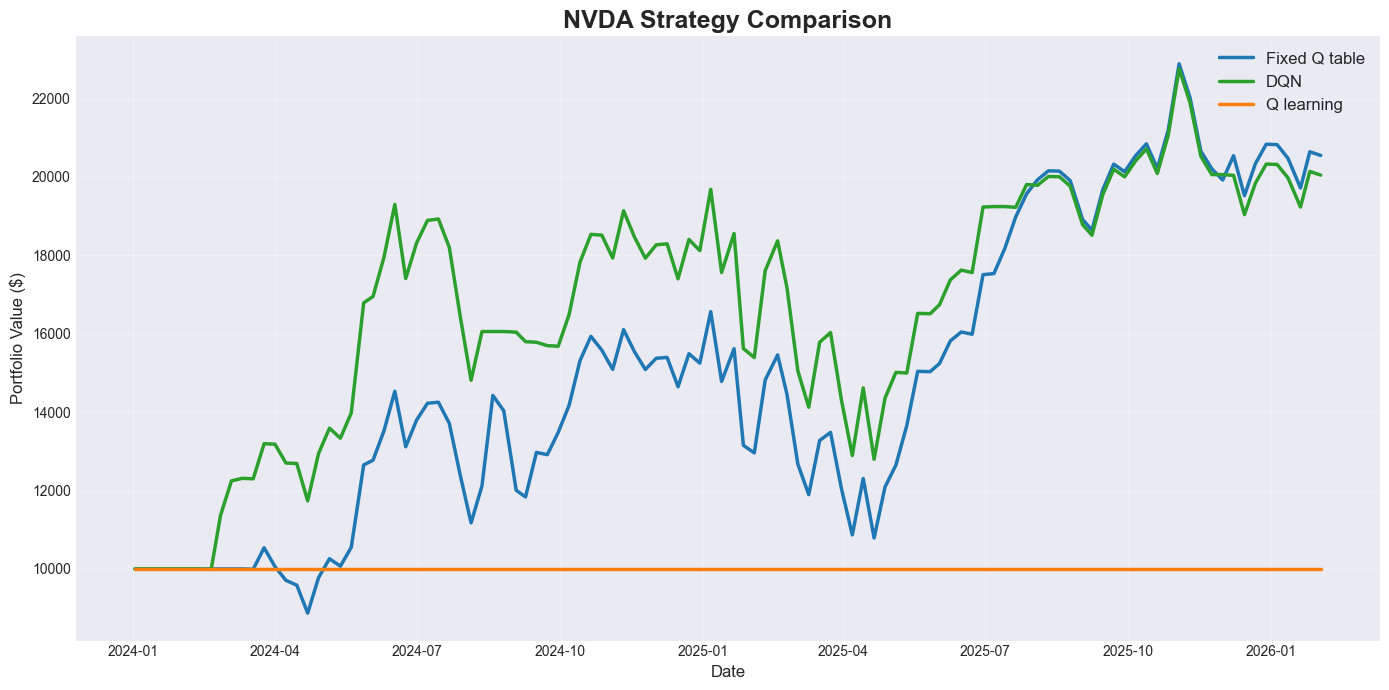

In [2]:
plot_ticker('NVDA')

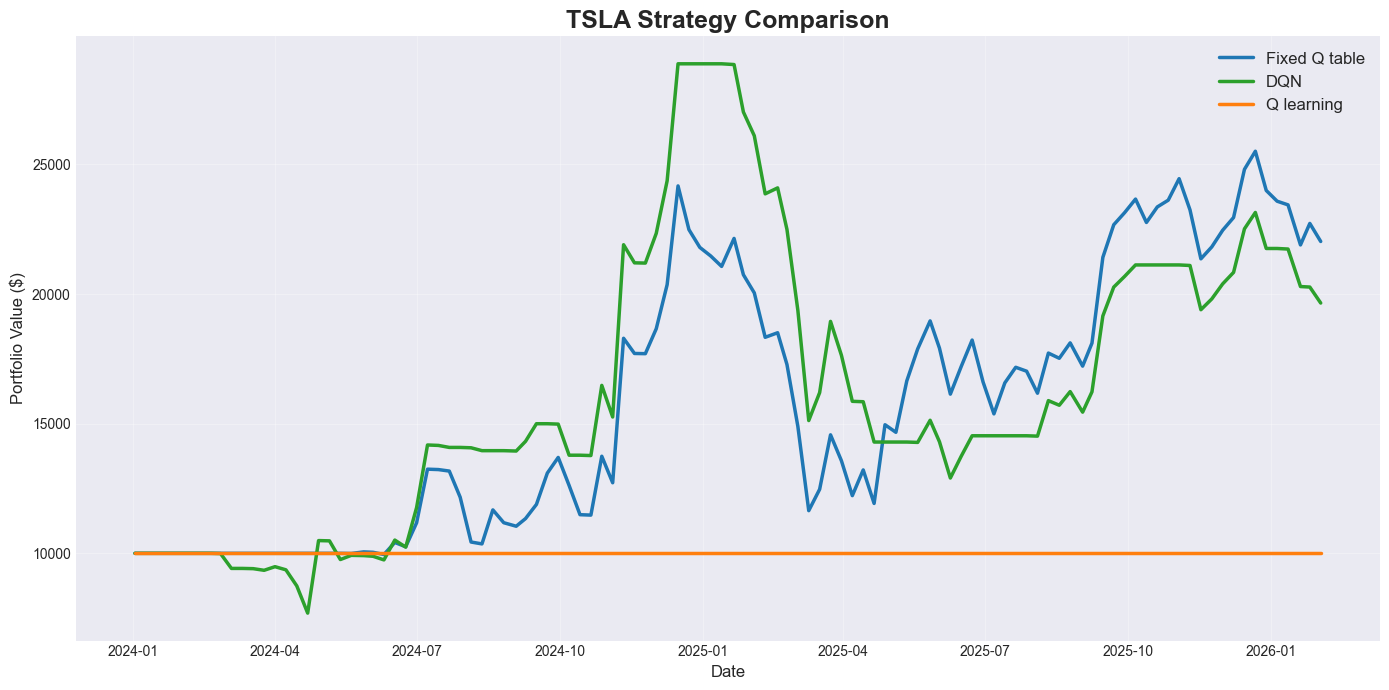

In [3]:
plot_ticker('TSLA')

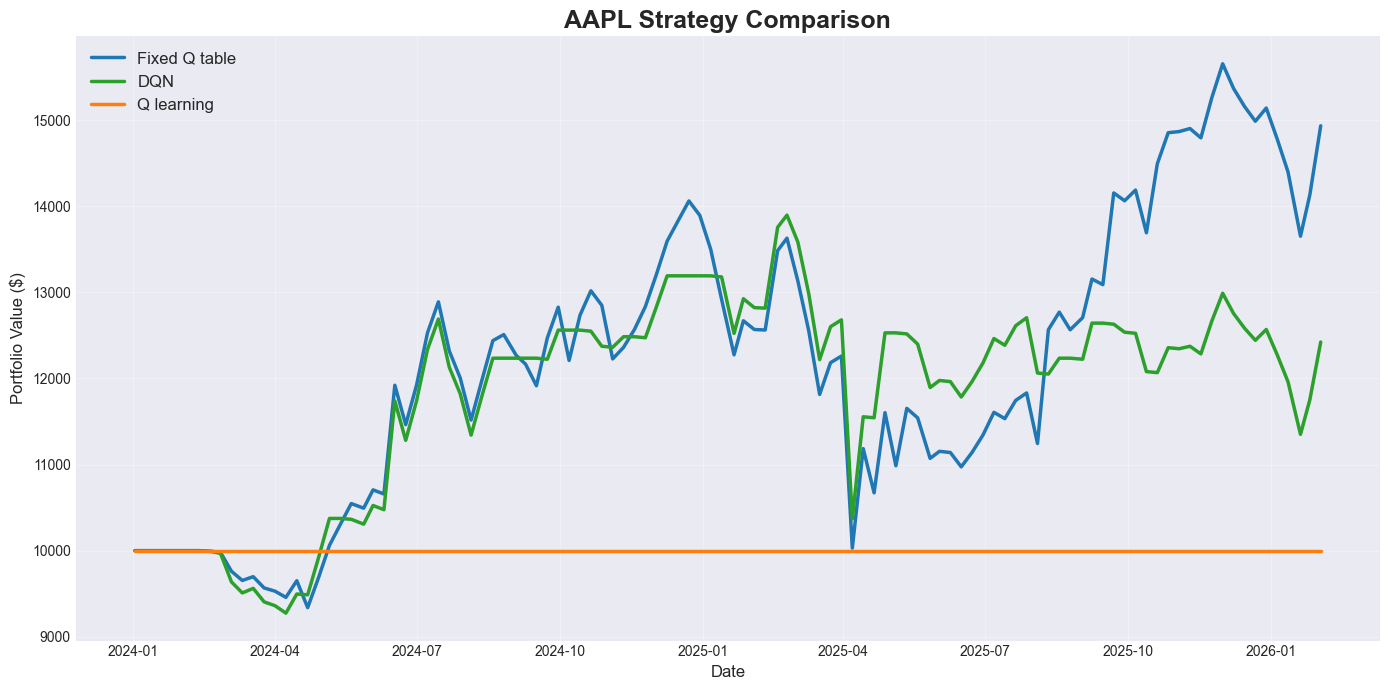

In [4]:
plot_ticker('AAPL')

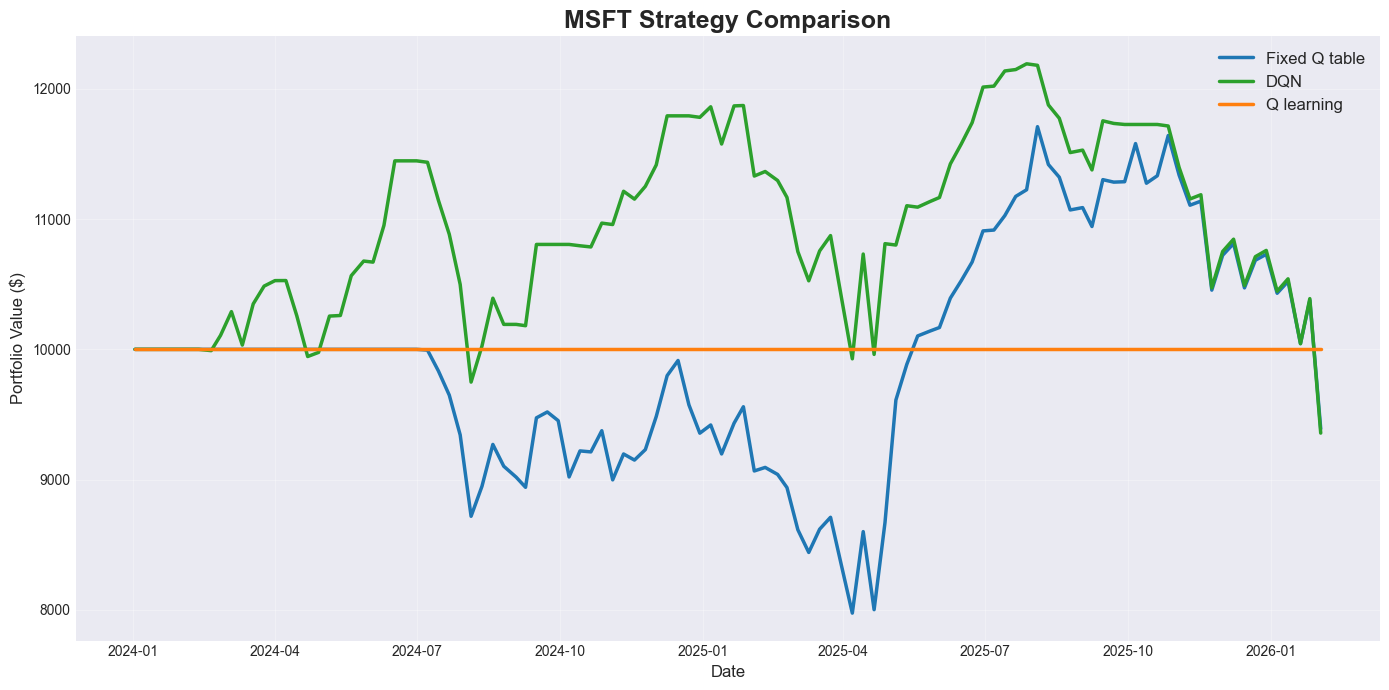

In [5]:
plot_ticker('MSFT')

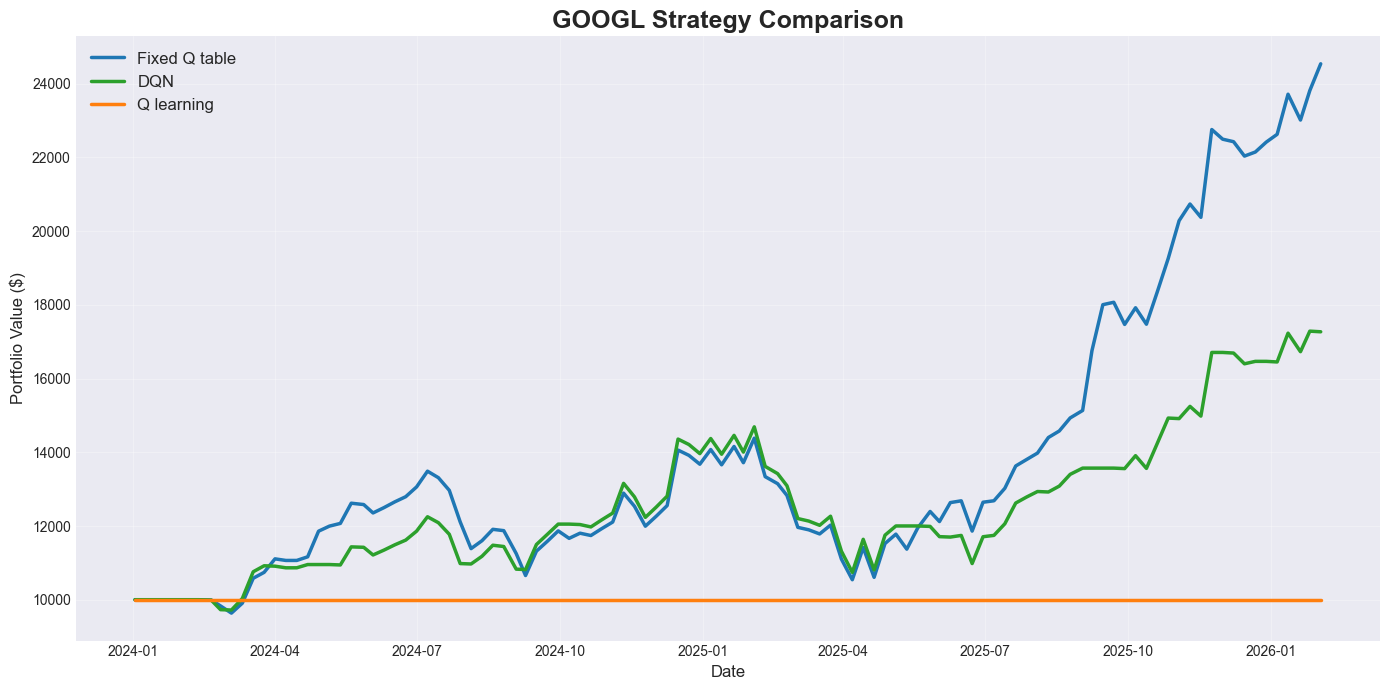

In [6]:
plot_ticker('GOOGL')

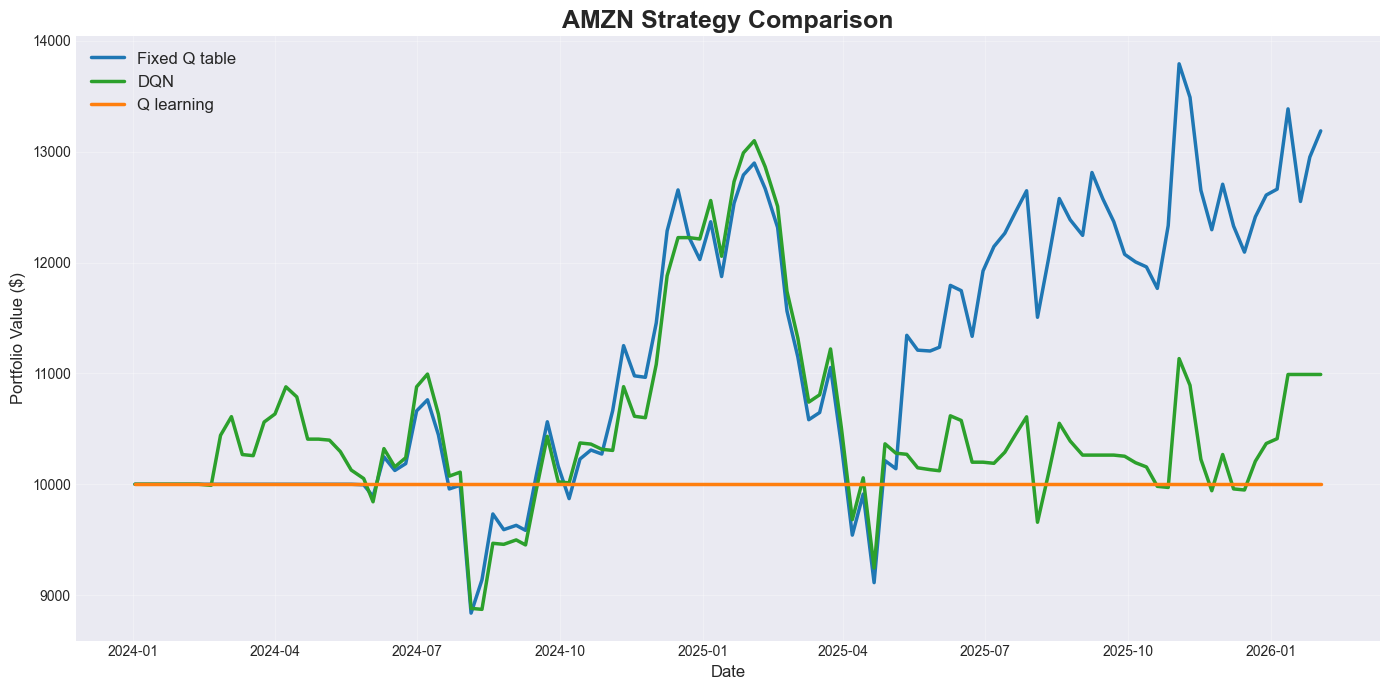

In [7]:
plot_ticker('AMZN')

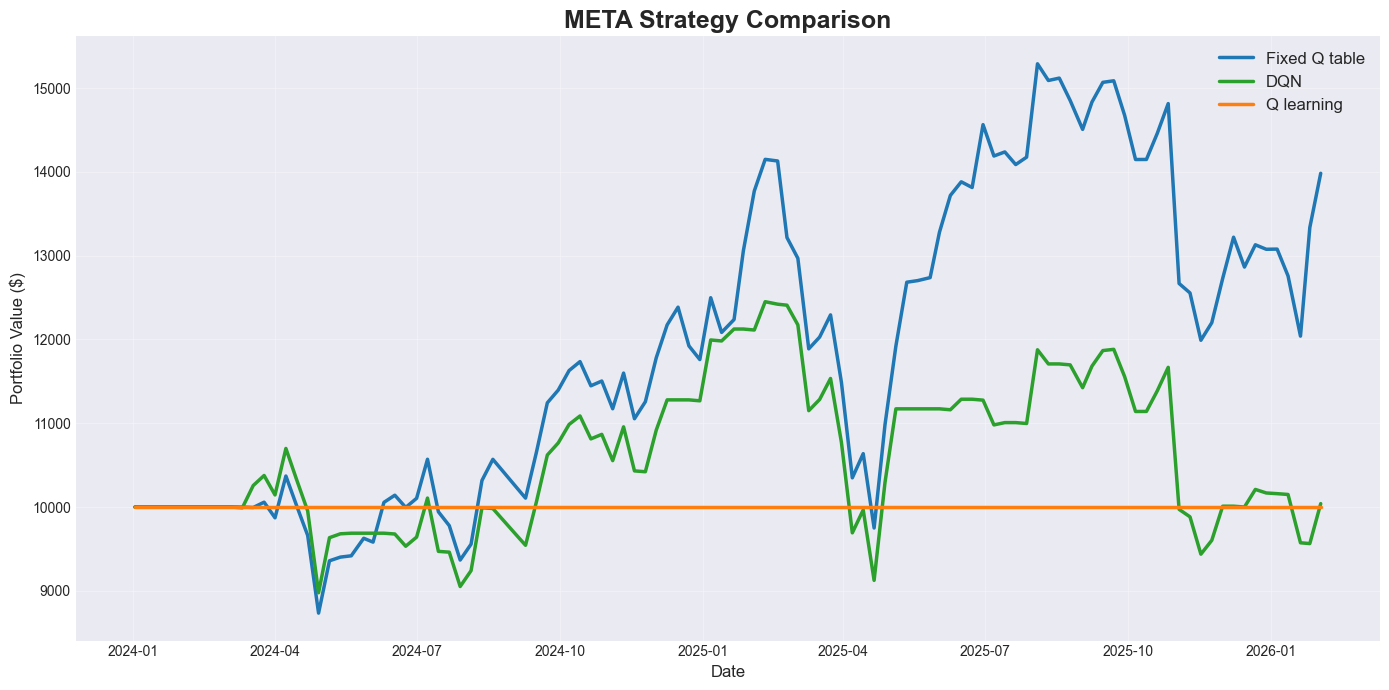

In [8]:
plot_ticker('META')

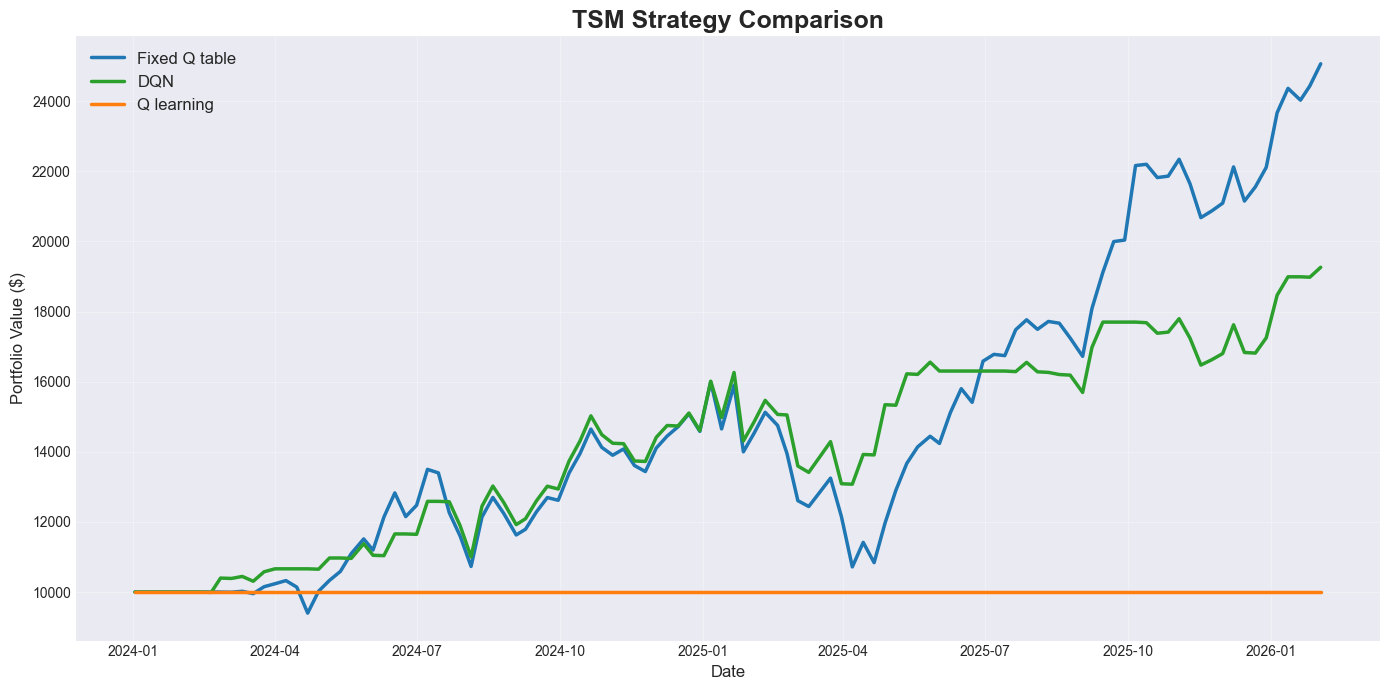

In [9]:
plot_ticker('TSM')

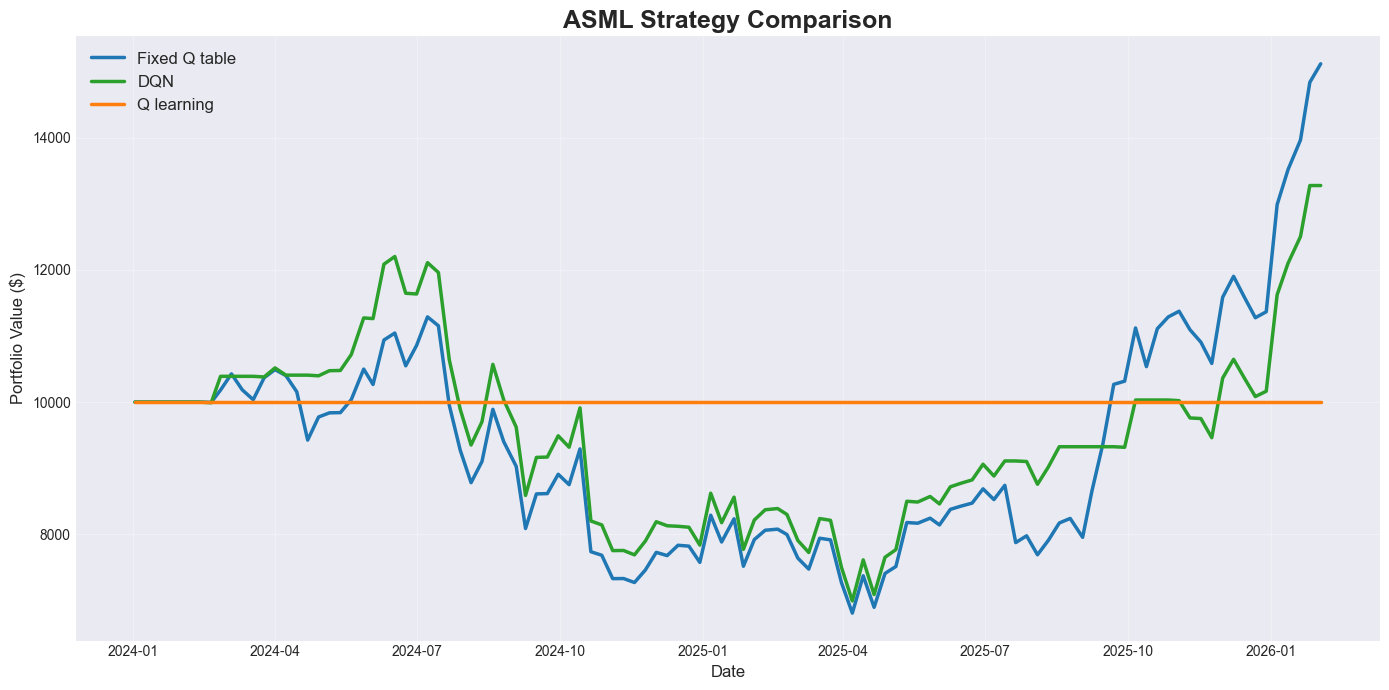

In [10]:
plot_ticker('ASML')